# arXiv in 3D: a yt nebula

Build a reproducible 3D IMSTE embedding of arXiv papers, then turn the point cloud into a glowing, multi-color volume with [yt volume rendering](https://yt-project.org/doc/visualizing/volume_rendering.html). Broad halos show the paper-domain density; brighter knots and a sparse star layer reveal the underlying embedding.

This is a visualization of text-vector neighborhoods, styled like an astronomical nebula. The colors identify broad arXiv domains; they do not represent physical quantities. yt traces rays through the gridded density field with transfer functions, rather than projecting the points into a flat scatter plot.


In [17]:
%load_ext autoreload
%autoreload 2
%config InlineBackend.figure_format = 'retina'

from pathlib import Path
import sys
import hashlib
import json
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import ipywidgets as widgets
from matplotlib.colors import to_rgb
from scipy.ndimage import gaussian_filter
from IPython.display import display
import yt
from yt.visualization.volume_rendering.api import ColorTransferFunction, PointSource, create_volume_source

PROJECT_ROOT = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / 'pyproject.toml').is_file() and (path / 'imste' / '__init__.py').is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise RuntimeError('Could not locate the IMSTE repository from the notebook working directory.')
for local_path in (PROJECT_ROOT, PROJECT_ROOT / 'notebooks' / 'src'):
    local_path = str(local_path)
    if local_path in sys.path:
        sys.path.remove(local_path)
    sys.path.insert(0, local_path)

from arxiv_dataset import load_arxiv_dataset
from arxiv_imste import select_arxiv_experiment_subset
from imste import IteratedMinimumSpanningTreeEmbedder

DATA_DIR = PROJECT_ROOT / 'data' / 'arxiv'
CACHE_DIR = DATA_DIR / 'cache'
CACHE_DIR.mkdir(parents=True, exist_ok=True)
ASSET_DIR = PROJECT_ROOT / 'notebooks' / 'assets'
ASSET_DIR.mkdir(parents=True, exist_ok=True)

papers, X_full, data_manifest = load_arxiv_dataset(DATA_DIR)
print(f'arXiv corpus: {len(papers):,} papers × {X_full.shape[1]:,} features')
print(f'yt version: {yt.__version__}')


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
arXiv corpus: 3,233,620 papers × 384 features
yt version: 4.4.4


## Choose a balanced paper sample

The default is 2,500 papers per broad domain. Raise it for finer filaments; lower it for a faster preview. The 3D layout is cached by both sample and IMSTE settings.


In [18]:
TARGET_PER_CLASS = 1500
RANDOM_STATE = int(data_manifest['random_state'])

primary_category = papers['categories'].fillna('unknown').str.split().str[0]
archive = primary_category.str.split('.').str[0]
domain_names = {
    'cs': 'computer science', 'math': 'mathematics', 'eess': 'engineering',
    'stat': 'statistics', 'q-bio': 'biology', 'q-fin': 'finance', 'econ': 'economics',
}
domain = archive.map(domain_names).fillna('physics')
class_order = domain.value_counts().index.tolist()
labels_full = pd.Categorical(domain, categories=class_order)
counts = domain.value_counts()
PER_CLASS = min(TARGET_PER_CLASS, int(counts.min()))
if PER_CLASS < TARGET_PER_CLASS:
    print(f'Capped at {PER_CLASS:,} papers per domain by the smallest class.')

X_experiment, labels, subset_id = select_arxiv_experiment_subset(
    X_full,
    labels_full,
    dataset_id=data_manifest['dataset_id'],
    mode='balanced',
    sample_size=PER_CLASS * len(class_order),
    random_state=RANDOM_STATE,
)
X_experiment = np.asarray(X_experiment, dtype=np.float32)
labels = np.asarray(labels).astype(str)
print(f'Balanced sample: {len(labels):,} papers ({PER_CLASS:,} per domain), ID {subset_id}')
display(pd.Series(labels).value_counts().sort_index().rename('papers').to_frame())

IMSTE_3D_SETTINGS = {
    'n_components': 3,
    'n_msts': 4,
    'n_epochs': 1000,
    'batch_size': 32_768,
    'learning_rate': 0.05,
    'negative_ratio': 1,
    'lambda_rep': 0.2,
    'random_state': RANDOM_STATE,
    'device': 'auto',
    'mst_method': 'famst',
    'mst_neighbor_backend': 'rinnd',
    'mst_neighbors': 15,
    'mst_inter_component_edges': 5,
    'pca_init': True,
    'pca_init_scaling': 'global',
    'multilevel_init': True,
    'multilevel_reduction_ratio': 8,
    'multilevel_base_size': 512,
    'multilevel_epochs': 10,
    # Keep the geometry truly 3D; the optional refinement stages are 2D.
    'gravity_mode': None,
    'mean_shift_iterations': 0,
}
cache_payload = {'subset_id': subset_id, 'settings': IMSTE_3D_SETTINGS}
cache_key = hashlib.sha256(
    json.dumps(cache_payload, sort_keys=True).encode()
).hexdigest()[:16]
EMBEDDING_CACHE = CACHE_DIR / f'arxiv_imste_3d_{cache_key}.npz'

if EMBEDDING_CACHE.is_file():
    with np.load(EMBEDDING_CACHE, allow_pickle=False) as saved:
        Z_3D = saved['embedding'].astype(np.float32, copy=False)
    print(f'Loaded cached 3D IMSTE embedding: {EMBEDDING_CACHE.name}')
else:
    fit_started = time.perf_counter()
    estimator_3d = IteratedMinimumSpanningTreeEmbedder(**IMSTE_3D_SETTINGS)
    Z_3D = estimator_3d.fit_transform(X_experiment).astype(np.float32, copy=False)
    fit_seconds = time.perf_counter() - fit_started
    np.savez_compressed(
        EMBEDDING_CACHE,
        embedding=Z_3D,
        subset_id=np.asarray(subset_id),
        settings_json=np.asarray(json.dumps(IMSTE_3D_SETTINGS, sort_keys=True)),
    )
    print(f'3D IMSTE fit: {fit_seconds:.1f} s; cached as {EMBEDDING_CACHE.name}')

# Put the cloud into a padded, isotropic cube without distorting its 3D shape.
cloud_center = np.median(Z_3D, axis=0)
centered = Z_3D - cloud_center
cloud_radius = max(float(np.quantile(np.linalg.norm(centered, axis=1), 0.995)), 1e-9)
CLOUD_POINTS = np.clip(0.86 * centered / cloud_radius, -0.94, 0.94).astype(np.float32)


Balanced sample: 12,000 papers (1,500 per domain), ID 92c8443e96938c02d912


,papers
biology,1500
computer science,1500
economics,1500
engineering,1500
finance,1500
mathematics,1500
physics,1500
statistics,1500


3D IMSTE fit: 3.4 s; cached as arxiv_imste_3d_191428ec1cee8ed0.npz


## Inspect the 3D embedding

This point view is a quick orientation check. The main result below is a ray-cast volume, not this scatter plot.


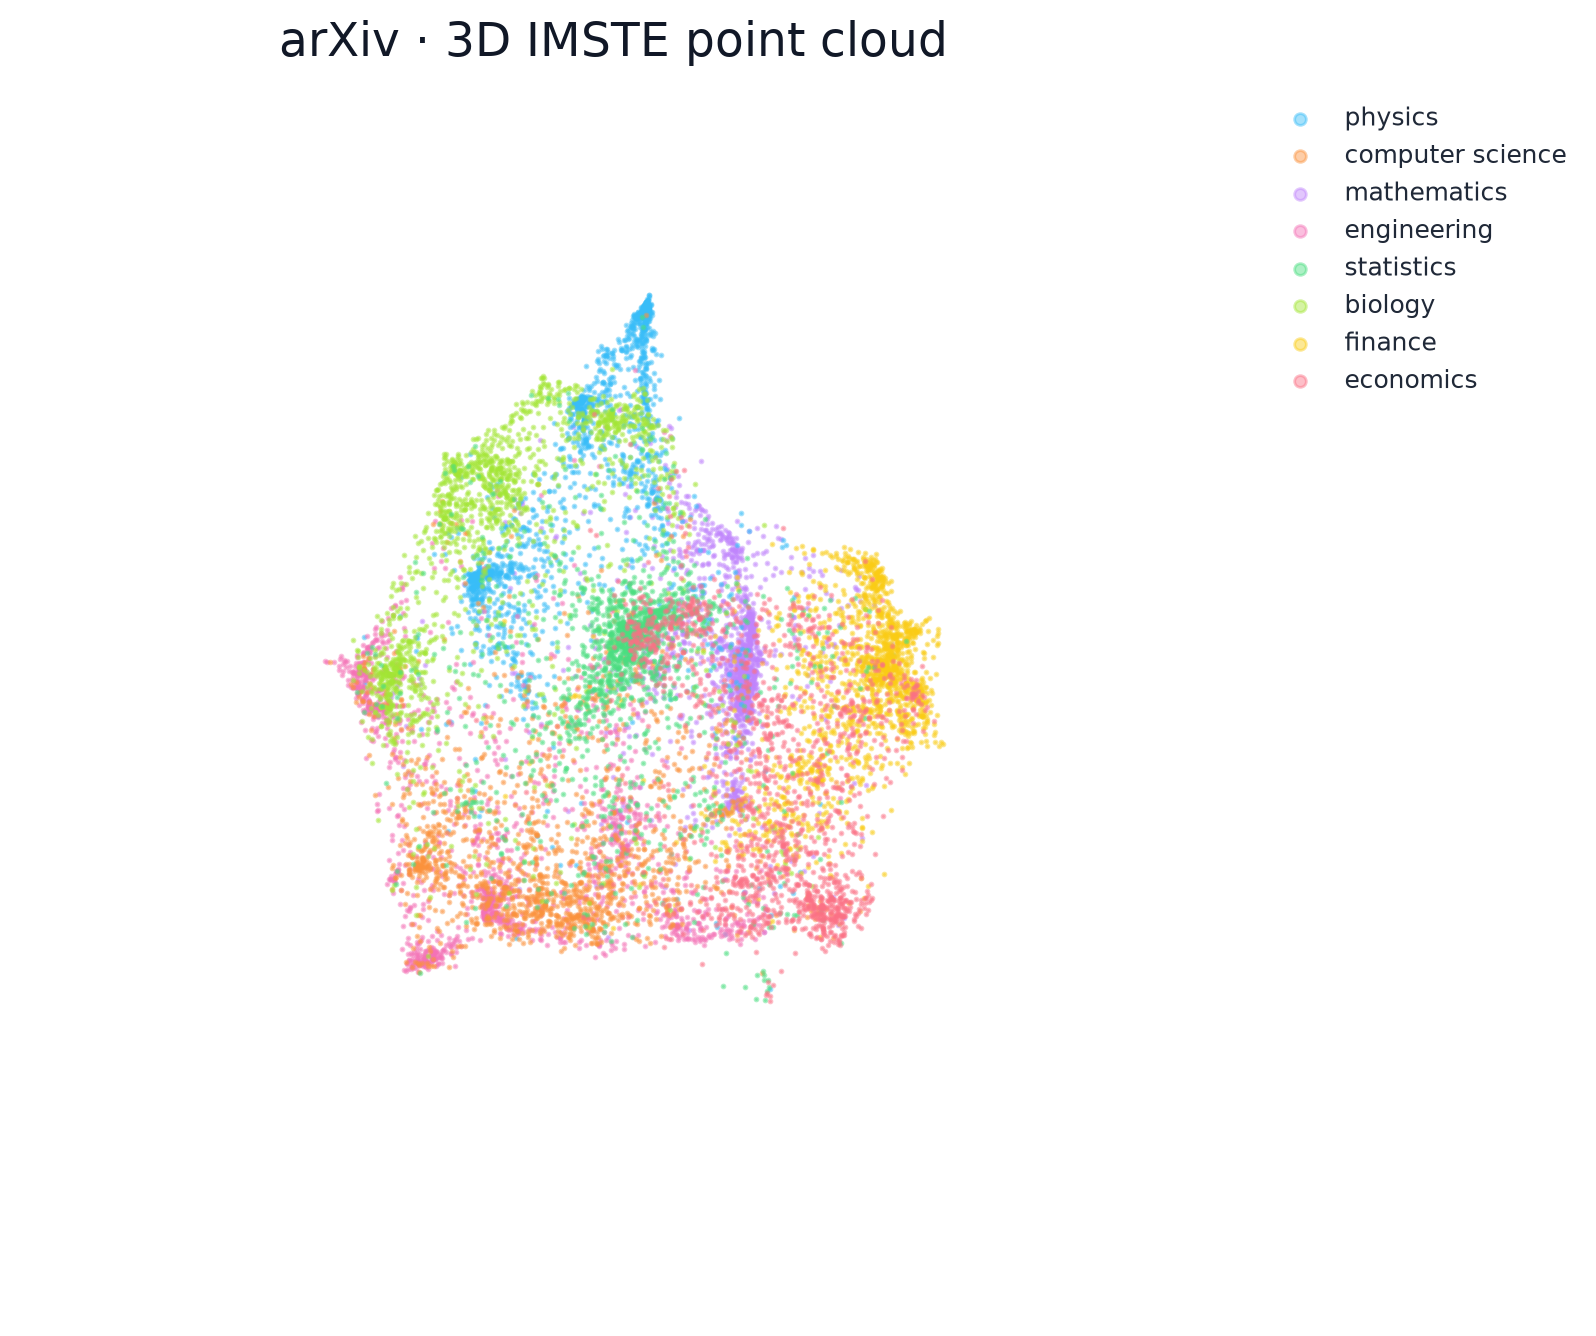

In [19]:
DOMAIN_PALETTE = ['#38bdf8', '#fb923c', '#c084fc', '#f472b6',
                  '#4ade80', '#a3e635', '#facc15', '#fb7185']
DOMAIN_COLORS = {
    name: to_rgb(DOMAIN_PALETTE[index % len(DOMAIN_PALETTE)])
    for index, name in enumerate(class_order)
}
point_colors = np.asarray([DOMAIN_COLORS[label] for label in labels])

fig = plt.figure(figsize=(9, 8), facecolor='white')
ax = fig.add_subplot(111, projection='3d', facecolor='white')
for name in class_order:
    mask = labels == name
    ax.scatter(*CLOUD_POINTS[mask].T, s=1.1, alpha=0.45,
               color=DOMAIN_COLORS[name], label=name, depthshade=False)
ax.set_axis_off()
ax.view_init(elev=24, azim=36)
ax.set_box_aspect((1, 1, 1))
ax.legend(loc='upper left', bbox_to_anchor=(1.0, 1.0), frameon=False,
          labelcolor='#202938', fontsize=9, markerscale=4)
fig.suptitle('arXiv · 3D IMSTE point cloud', color='#111827', fontsize=17, y=0.92)
plt.show()


## Build the nebula volume with yt

Each paper contributes to a domain-specific density channel. A narrow Gaussian core preserves filaments and knots, while a wider faint halo creates the gas-like bloom. yt composites the channels through per-domain color and opacity transfer functions.


In [20]:
GRID_SIZE = 72
CORE_SIGMA = 0.80
HALO_SIGMA = 2.25
HALO_MIX = 0.24

volume_fields = {}
for index, name in enumerate(class_order):
    mask = labels == name
    counts_3d, _ = np.histogramdd(
        CLOUD_POINTS[mask],
        bins=GRID_SIZE,
        range=((-1, 1), (-1, 1), (-1, 1)),
    )
    counts_3d = counts_3d.astype(np.float32)
    core = gaussian_filter(counts_3d, sigma=CORE_SIGMA, mode='constant')
    halo = gaussian_filter(counts_3d, sigma=HALO_SIGMA, mode='constant')
    emissivity = core + HALO_MIX * halo
    positive = emissivity[emissivity > 0]
    scale = max(float(np.quantile(positive, 0.997)), 1e-8)
    emissivity = np.clip(emissivity / scale, 0.0, 1.0)
    volume_fields[f'domain_{index}'] = (emissivity.astype(np.float32), 'dimensionless')

bbox = np.asarray([[-1, 1], [-1, 1], [-1, 1]], dtype=np.float64)
ds = yt.load_uniform_grid(
    volume_fields,
    domain_dimensions=(GRID_SIZE, GRID_SIZE, GRID_SIZE),
    length_unit=1.0,
    bbox=bbox,
    nprocs=1,
    periodicity=(False, False, False),
    dataset_name='arxiv_3d_nebula',
)
print(f'yt volume: {GRID_SIZE}³ cells, {len(class_order)} domain emission fields')


yt : [INFO     ] 2026-11-13 22:39:34,239 Parameters: current_time              = 0.0
yt : [INFO     ] 2026-11-13 22:39:34,240 Parameters: domain_dimensions         = [72 72 72]
yt : [INFO     ] 2026-11-13 22:39:34,240 Parameters: domain_left_edge          = [-1. -1. -1.]
yt : [INFO     ] 2026-11-13 22:39:34,240 Parameters: domain_right_edge         = [1. 1. 1.]
yt : [INFO     ] 2026-11-13 22:39:34,241 Parameters: cosmological_simulation   = 0


yt volume: 72³ cells, 8 domain emission fields


## Render the volume

Use the azimuth and elevation sliders to orbit the view. Each slider rerenders the same yt volume when released. The grid and image are kept moderate so angle changes stay reasonably quick. The sparse points add star-like highlights over the transparent gas volume.


In [21]:
from yt.visualization.volume_rendering.api import Scene

scene = yt.create_scene(
    ds,
    field=('stream', 'domain_0'),
)

# One volume source per arXiv domain: low-opacity color clouds, white-hot cores.
for index, name in enumerate(class_order):
    field = ('stream', f'domain_{index}')
    source = scene[0] if index == 0 else create_volume_source(ds, field)
    source.set_field(field)
    source.set_log(True)
    color = np.asarray(DOMAIN_COLORS[name], dtype=np.float64)
    bounds = (1e-3, 1.0)
    tf = ColorTransferFunction(np.log10(bounds))
    tint = 0.10 + 0.90 * color
    tf.add_gaussian(-2.45, 0.48, [*(0.72 * tint), 0.045])
    tf.add_gaussian(-1.50, 0.38, [*tint, 0.12])
    tf.add_gaussian(-0.50, 0.26, [*(0.65 * tint + 0.35), 0.24])
    source.tfh.tf = tf
    source.tfh.bounds = bounds
    if index:
        scene.add_source(source)

# A restrained star layer keeps the underlying points legible through the gas.
rng = np.random.default_rng(RANDOM_STATE)
star_count = min(520, len(CLOUD_POINTS))
star_rows = rng.choice(len(CLOUD_POINTS), size=star_count, replace=False)
star_positions = ds.arr(CLOUD_POINTS[star_rows], 'code_length')
star_colors = np.ones((star_count, 4), dtype=np.float64)
star_colors[:, :3] = 0.52 + 0.48 * point_colors[star_rows]
star_colors[:, 3] = 0.78
scene.add_source(PointSource(star_positions, colors=star_colors))

scene.camera.focus = ds.domain_center
scene.camera.width = ds.domain_width * 0.96
scene.camera.resolution = 360
VIEW_IMAGE = ASSET_DIR / 'arxiv_3d_yt_nebula.png'

azimuth = widgets.IntSlider(
    value=35, min=0, max=345, step=15,
    description='Azimuth', continuous_update=False,
    layout=widgets.Layout(width='360px'),
)
elevation = widgets.IntSlider(
    value=30, min=-50, max=55, step=5,
    description='Elevation', continuous_update=False,
    layout=widgets.Layout(width='360px'),
)
view_image = widgets.Image(
    format='png',
    layout=widgets.Layout(width='480px', height='480px'),
)

def _render_view(change=None):
    az = np.deg2rad(azimuth.value)
    el = np.deg2rad(elevation.value)
    normal = [np.cos(el) * np.cos(az), np.cos(el) * np.sin(az), np.sin(el)]
    scene.camera.switch_orientation(
        normal_vector=normal,
        north_vector=[0.0, 0.0, 1.0],
    )
    scene.save(str(VIEW_IMAGE), sigma_clip=4.0)
    view_image.value = VIEW_IMAGE.read_bytes()

azimuth.observe(_render_view, names='value')
elevation.observe(_render_view, names='value')
_render_view()
display(widgets.VBox([
    widgets.HBox([azimuth, elevation]),
    view_image,
]))


yt : [WARNING  ] 2026-11-13 22:39:34,308 No previously rendered image found, rendering now.
yt : [INFO     ] 2026-11-13 22:39:34,309 Rendering scene (Can take a while).
yt : [INFO     ] 2026-11-13 22:39:34,310 Creating volume
yt : [INFO     ] 2026-11-13 22:39:41,536 Saving rendered image to /Users/f.costa/Documents/Projects/Repositories/ACTIVE/IteratedMinimumSpanningTree/notebooks/assets/arxiv_3d_yt_nebula.png
